In [90]:
import pandas as pd
import numpy as np

# Membaca dataset
df = pd.read_csv("paket_a_transaksi_pos_2024_2025.csv")

# Menampilkan data awal
print("Jumlah data:", df.shape)
display(df.head())

# Melihat informasi dataset
df.info()

Jumlah data: (5030, 9)


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


<class 'pandas.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   id_transaksi   5030 non-null   str  
 1   tanggal        5030 non-null   str  
 2   kode_gerai     5030 non-null   str  
 3   kode_kasir     4769 non-null   str  
 4   kode_produk    5030 non-null   str  
 5   jumlah         5030 non-null   int64
 6   harga_satuan   5030 non-null   str  
 7   diskon_persen  5030 non-null   int64
 8   status         5030 non-null   str  
dtypes: int64(2), str(7)
memory usage: 578.2 KB


In [91]:
# Memeriksa missing value
print("Missing value sebelum diperbaiki:")
print(df.isnull().sum())

# Mengisi kode kasir yang kosong
df["kode_kasir"] = df["kode_kasir"].fillna("TIDAK DIKETAHUI")

# Memeriksa kembali missing value
print("\nMissing value setelah diperbaiki:")
print(df.isnull().sum())

Missing value sebelum diperbaiki:
id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64

Missing value setelah diperbaiki:
id_transaksi     0
tanggal          0
kode_gerai       0
kode_kasir       0
kode_produk      0
jumlah           0
harga_satuan     0
diskon_persen    0
status           0
dtype: int64


In [92]:
# Menghapus data duplikat yang sama persis
df = df.drop_duplicates()

# Membersihkan format tanggal
df["tanggal"] = pd.to_datetime(
    df["tanggal"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Mengubah harga satuan menjadi angka
df["harga_satuan"] = (
    df["harga_satuan"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)

df["harga_satuan"] = pd.to_numeric(
    df["harga_satuan"],
    errors="coerce"
)

# Mengubah jumlah dan diskon menjadi angka
df["jumlah"] = pd.to_numeric(df["jumlah"], errors="coerce")
df["diskon_persen"] = pd.to_numeric(
    df["diskon_persen"], errors="coerce"
)

# Menangani data numerik yang kosong
df["jumlah"] = df["jumlah"].fillna(0)
df["diskon_persen"] = df["diskon_persen"].fillna(0)

# Menghapus baris yang tanggal atau harga satuannya tidak valid
df = df.dropna(subset=["tanggal", "harga_satuan"])

# Menampilkan hasil pembersihan
print("Jumlah data setelah dibersihkan:", df.shape)
display(df.head())

Jumlah data setelah dibersihkan: (5000, 9)


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-02-06,G09,K011,RMT1402,4,"13,000.00",0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,"21,000.00",0,SELESAI
2,TRX0244483,2024-04-09,G11,K029,RMT1407,3,"7,500.00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,"6,500.00",0,SELESAI
4,TRX0243509,2025-03-26,G05,K016,RMT1407,1,"6,000.00",0,SELESAI


In [96]:
# Memeriksa jumlah barang yang tidak wajar
data_mencurigakan = df[
    (df["jumlah"] < 0) |
    (df["jumlah"] > 100)
]

print("Data dengan jumlah barang yang perlu diperiksa:")
display(data_mencurigakan[
    ["id_transaksi", "jumlah", "status"]
])

Data dengan jumlah barang yang perlu diperiksa:


,id_transaksi,jumlah,status
32,TRX0241782,-6,SELESAI
41,TRX0240181,-12,SELESAI
87,TRX0243886,2375,SELESAI
90,TRX0240898,-3,SELESAI
195,TRX0244719,-1,SELESAI
244,TRX0243257,1456,SELESAI
467,TRX0243696,892,SELESAI
660,TRX0242847,661,BATAL
723,TRX0243147,-3,SELESAI
847,TRX0241754,-1,BATAL


In [97]:
# Menghitung pendapatan setelah diskon
df["pendapatan"] = (
    df["jumlah"] *
    df["harga_satuan"] *
    (1 - df["diskon_persen"] / 100)
)

# Memisahkan tahun dari tanggal transaksi
df["tahun"] = df["tanggal"].dt.year

# Menampilkan jumlah transaksi berdasarkan status
print("Jumlah transaksi berdasarkan status:")
print(df["status"].value_counts())

# Hanya transaksi SELESAI yang dihitung sebagai pendapatan
df_selesai = df[df["status"].str.upper() == "SELESAI"].copy()

# Mengambil data tahun 2024 dan 2025
df_tahun = df_selesai[
    df_selesai["tahun"].isin([2024, 2025])
]

# Menghitung total pendapatan per tahun
total_pendapatan = df_tahun.groupby("tahun")["pendapatan"].sum()

print("\nTOTAL PENDAPATAN PER TAHUN")
print("--------------------------------")

for tahun in [2024, 2025]:
    total = total_pendapatan.get(tahun, 0)
    print(f"Pendapatan tahun {tahun}: Rp {total:,.0f}")

Jumlah transaksi berdasarkan status:
status
SELESAI    4719
BATAL       191
RETUR        90
Name: count, dtype: int64

TOTAL PENDAPATAN PER TAHUN
--------------------------------
Pendapatan tahun 2024: Rp 386,237,375
Pendapatan tahun 2025: Rp 257,085,100


HASIL PENDAPATAN TAHUN 2024 DAN 2025


,tahun,jumlah_transaksi,total_pendapatan
0,2024,2349,"386,237,375.00"
1,2025,2370,"257,085,100.00"


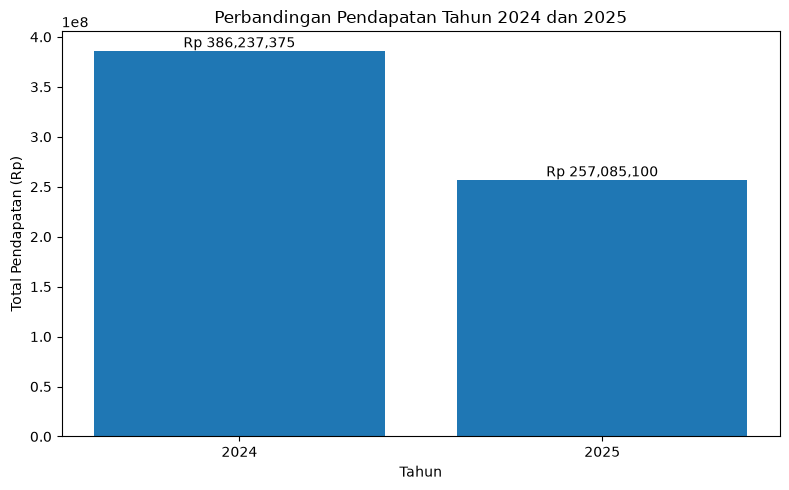

In [100]:
import matplotlib.pyplot as plt

# Membuat tabel hasil pendapatan
hasil = df_tahun.groupby("tahun").agg(
    jumlah_transaksi=("id_transaksi", "count"),
    total_pendapatan=("pendapatan", "sum")
).reset_index()

# Menampilkan tabel
print("HASIL PENDAPATAN TAHUN 2024 DAN 2025")
display(hasil)

# Membuat diagram batang
plt.figure(figsize=(8, 5))

plt.bar(
    hasil["tahun"].astype(str),
    hasil["total_pendapatan"]
)

plt.title("Perbandingan Pendapatan Tahun 2024 dan 2025")
plt.xlabel("Tahun")
plt.ylabel("Total Pendapatan (Rp)")

# Menampilkan angka di atas batang
for i, nilai in enumerate(hasil["total_pendapatan"]):
    plt.text(i, nilai, f"Rp {nilai:,.0f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

In [99]:
# Menyimpan dataset yang sudah dibersihkan
df.to_csv("dataset_transaksi_bersih.csv", index=False)

# Menyimpan hasil perhitungan pendapatan
hasil.to_csv("hasil_pendapatan_2024_2025.csv", index=False)

print("File berhasil disimpan!")

File berhasil disimpan!
